**LEITURA DO DATASET**

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/ai_human.csv")

**TESTE COM DATASET**

In [2]:
print("=" * 50)
print("ℹ️ DATASET BASIC INFORMATION")
print("=" * 50)
print(f"\nDataset Shape: {df.shape}")
print(f"\nColunms: {df.columns.to_list()}")
print("\nData Type:")
print(f"{df.dtypes}")
print("\n5 First and Last Rows:")
display(df)
print(f"\nMissing Values: \n{df.isnull().sum()}")
print(f"\nValue Counts: \n{df["generated"].value_counts()}")

df['label'] = df['generated'].apply(lambda x: 'AI' if x == 1.0 else "Human")
print(f"\nNew label created:")
print(f"{df['label'].value_counts()}")

print(f"\nBasic Statistics for 'generated' column:")
print(df['generated'].describe())

ℹ️ DATASET BASIC INFORMATION

Dataset Shape: (487235, 2)

Colunms: ['text', 'generated']

Data Type:
text             str
generated    float64
dtype: object

5 First and Last Rows:


,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0
...,...,...
487230,Tie Face on Mars is really just a big misunder...,0.0
487231,The whole purpose of democracy is to create a ...,0.0
487232,I firmly believe that governments worldwide sh...,1.0
487233,I DFN't agree with this decision because a LFT...,0.0



Missing Values: 
text         0
generated    0
dtype: int64

Value Counts: 
generated
0.0    305797
1.0    181438
Name: count, dtype: int64

New label created:
label
Human    305797
AI       181438
Name: count, dtype: int64

Basic Statistics for 'generated' column:
count    487235.000000
mean          0.372383
std           0.483440
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           1.000000
Name: generated, dtype: float64


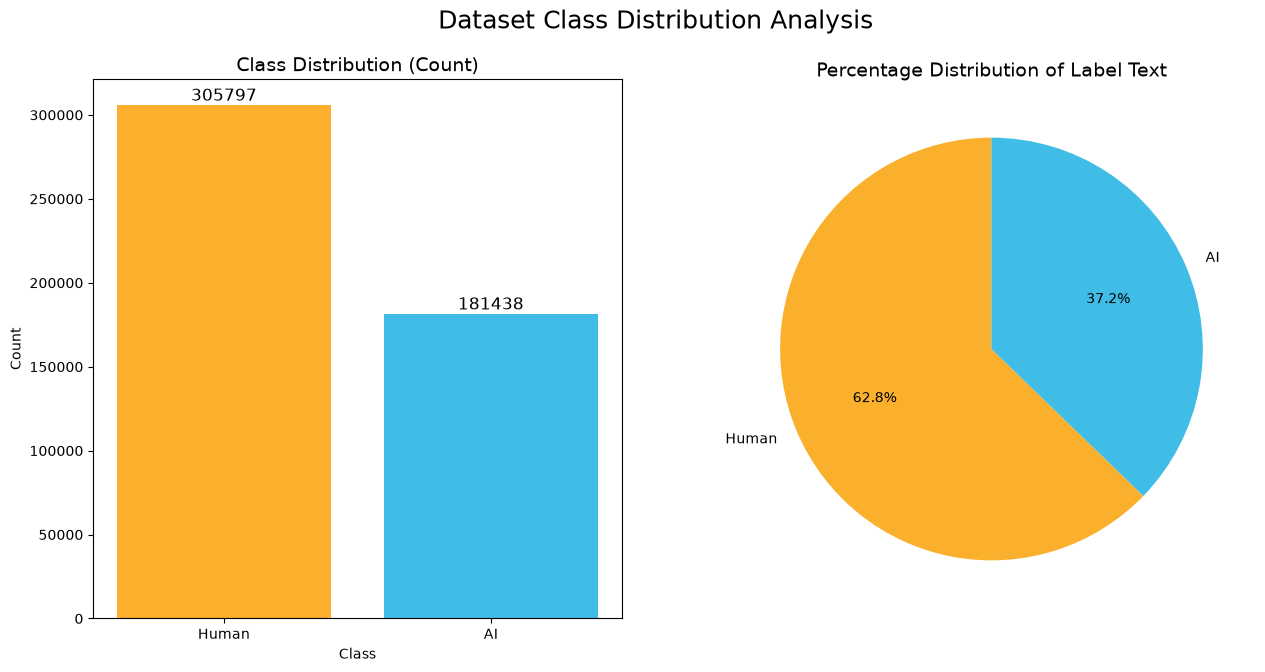

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = df['label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

#  Bar chart for class distribution 
axes[0].bar(class_counts.index, class_counts.values, color={'#40bde6', '#faaf2d'})
for i, val in enumerate(class_counts.values):
    axes[0].text(i, val + 0.001*max(class_counts.values), str(val), ha='center', va='bottom', fontsize=12)
axes[0].set_title('Class Distribution (Count)', fontsize=14)
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')

#  Pie chart for class percentage
axes[1].pie(class_counts.values, labels=class_counts.index, colors={'#40bde6', '#faaf2d'}, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Percentage Distribution of Label Text', fontsize=14)

plt.suptitle('Dataset Class Distribution Analysis', fontsize=18)
plt.show()

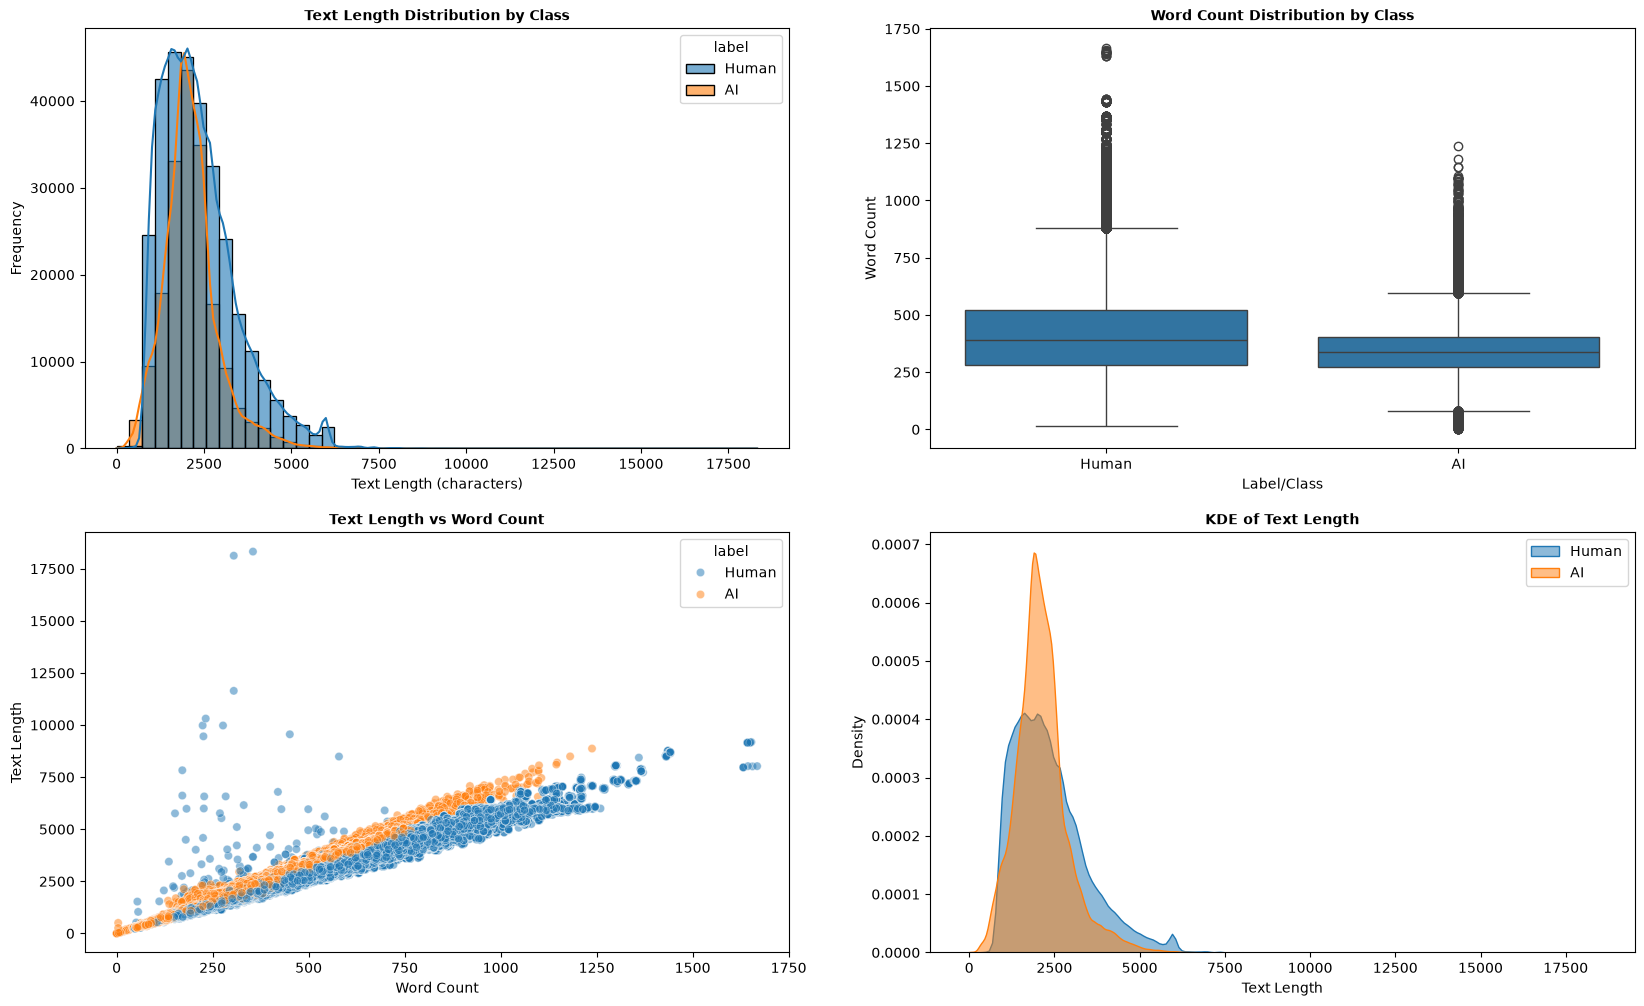

In [8]:
# Text Length Analysis
df['text_len'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

fig = plt.figure(figsize=(20, 12))

#  Text Length Distribution
plt.subplot(2, 2, 1)
sns.histplot(data=df, x='text_len', hue='label', kde=True, alpha=0.6, bins=50)
plt.title('Text Length Distribution by Class', fontsize=10, fontweight='bold')
plt.xlabel('Text Length (characters)')
plt.ylabel('Frequency')

# Text Word Count Distribution
plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='label', y='word_count')
plt.title('Word Count Distribution by Class', fontsize=10, fontweight='bold')
plt.xlabel('Label/Class')
plt.ylabel('Word Count')

# Text Length vs Word Count
plt.subplot(2, 2, 3)
sns.scatterplot(data=df, x='word_count', y='text_len', hue='label', alpha=0.5)
plt.title('Text Length vs Word Count', fontsize=10, fontweight='bold')
plt.xlabel('Word Count')
plt.ylabel('Text Length')

# Distribution of Text Length (KDE)
plt.subplot(2, 2, 4)
sns.kdeplot(data=df[df['label'] == 'Human']['text_len'], label='Human', fill=True,  alpha=0.5)
sns.kdeplot(data=df[df['label'] == 'AI']['text_len'], label='AI', fill=True, alpha=0.5)
plt.title('KDE of Text Length', fontsize=10, fontweight='bold')
plt.xlabel('Text Length')
plt.ylabel('Density')
plt.legend()


plt.show()
